# Prior-Assisted INR + Graph-CNN Reconstruction

This is per-asteroid neural optimization, not a pretrained lightcurve encoder. The coordinate SIREN deforms an ellipsoid; the graph network refines its fixed mesh topology. The convex LS+Lambert forward model and mean-normalized lightcurve MSE are unchanged.

The default `plain` GCN uses the stabilized training recipe. `residual` selects a smaller pre-normalized graph refiner for ablation; it has not shown a consistent shape-quality advantage. See [the experiment report](experiments/REPORT.md) for measured results and reproduction commands.

Both stages use the same cylinder normalization. With displacement $d=V-V_{\mathrm{reference}}$, optimization uses

$$
\mathcal L = \mathrm{MSE}_{\mathrm{train}}(\hat y,y) + \lambda_h d_{\mathrm{Chamfer}}(V,H) + \lambda_L\,\mathrm{mean}\big((d-\overline d_{\mathrm{neighbors}})^2\big) + \lambda_d\,\mathrm{mean}(d^2).
$$

**Stage 1 (convex prior)** uses weights $(\lambda_h,\lambda_L,\lambda_d)=(0.3,0.1,0)$ relative to the normalized ellipsoid, so the coarse INR mesh lands on the convex-hull shape. **Stage 2 (lightcurve-only refinement)** uses $(0,0.1,0)$ relative to the restored coarse mesh: the convex-hull term and the stage-1 tether are both removed, so the graph refiner can move the mesh away from the convex shape to fit the lightcurves. Only the one-ring smoothness on the deformation remains, as a mesh-validity safeguard; the cylinder normalization still bounds the mesh. Adam, gradient clipping, and plateau LR reduction are handled by `hac.lc2mesh.training`.

**Why Stage 2 now visibly differs from Stage 1.** With a held-out camera split, any larger Stage-2 deformation tends to raise the *held-out* MSE, so validation-based early stopping restored a checkpoint right next to the Stage-1 mesh — which is why the two used to look identical. Stage 2 therefore selects the checkpoint with the best **training** lightcurve fit (`SELECTION_STAGE2="training"`), letting the refinement move; a probe fixed `LR_GRAPH=1e-4` as the largest graph step that still did not degrade validation MSE. The refiner's INR stays nearly frozen (`LR_INR_STAGE2=1e-6`) because unfreezing the global field only worsened held-out MSE and shrank the movement.

A fixed 21/7 camera split preserves complete rotation sequences. Stage 1 still selects its checkpoint by held-out validation MSE. Validation never enters the gradient; in Stage 2 it is monitored, not optimized, and the notebook prints a warning if it rises (a sign the extra freedom is overfitting the observed cameras). Set `SELECTION_STAGE2="validation"` to fall back to the conservative behavior that stays close to Stage 1. It is a validation set, not an independent test set.

**Provenance caveat:** the external prior is an existing *simulated-lightcurve* convex inversion, while targets are real lightcurves. Its camera provenance is unverified, so validation is conditional on that prior, not a clean end-to-end holdout. True STL geometry is evaluation-only by default; an explicit opt-in retains oracle experiments. Better lightcurve fit does not by itself establish better geometry.

Notebook checkpoints are inference artifacts, not optimizer-resume checkpoints. The benchmark script also records source/data hashes and exports per-run JSON metrics and meshes.


In [1]:
import os
import time
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import trimesh

from hac.constants import OBSERVERS
from hac.data import get_model_folder, load_data
from hac.lc2mesh.data import create_ellipsoidal_prior_mesh
from hac.lc2mesh.forward_model import AsteroidForwardModel, observers_to_unit_tensor
from hac.lc2mesh.metrics import (
    compute_mse,
    compute_per_camera_metrics,
    mesh_reconstruction_metrics,
)
from hac.lc2mesh.model import LightcurveToMesh
from hac.lc2mesh.training import TrainingConfig, split_camera_indices, train_stage
from hac.lc2mesh.utils import (
    sample_convex_hull_surface,
    set_seed,
    setup_device,
    vertex_normals_from_faces,
)
from hac.lc2mesh.visualization import (
    plot_camera_grid,
    plot_interactive_mesh,
    plot_lightcurve_comparison,
)
from hac.mesh import normalize_mesh_to_challenge_cylinder

os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")
torch.set_default_dtype(torch.float32)
torch.use_deterministic_algorithms(True)

In [2]:
ASTEROID_ID = 10
CURVE_TYPE = "intensity"
SEED = 42
SPLIT_SEED = 1729
VALIDATION_FRACTION = 0.25
TARGET_GPU_ID = 7
PRIOR_SHAPE_TYPE = "ellipsoid"
REFERENCE_MESH_SOURCE = "convex_inversion"
ALLOW_ORACLE_REFERENCE = False
PROJECT_ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").exists())
WORKSPACE_DIR = PROJECT_ROOT / "workspaces" / "ishak"
CONVEX_INVERSION_DIR = WORKSPACE_DIR / "convex_inversions"

N_SUBDIVISIONS = 4
INR_HIDDEN_DIM = 128
INR_NUM_LAYERS = 4
COARSE_W0 = 30.0
INR_FINAL_INIT_SCALE = 1e-3
GCN_ARCHITECTURE = "plain"
GCN_HIDDEN_DIM = 64 if GCN_ARCHITECTURE == "residual" else 128
GCN_NUM_LAYERS = 4 if GCN_ARCHITECTURE == "residual" else 6
GCN_FINAL_INIT_SCALE = 1e-3
LAMBERT_WEIGHT = 0.5

STAGE1_STEPS = 2000
LR_INR_STAGE1 = 1e-4
LAMBDA_CHAMFER = 0.3
HULL_N_SAMPLES = 4096
STAGE2_STEPS = 2000
LR_GRAPH = 1e-4
LR_INR_STAGE2 = 1e-6
# Phase 2 fits the lightcurves only: no convex-hull loss and no tether to the
# stage-1 shape (only one-ring deformation smoothness remains, as a validity
# safeguard). SELECTION_STAGE2="training" keeps the checkpoint with the best
# lightcurve fit instead of the best held-out MSE, so the refined mesh actually
# leaves the convex stage-1 shape; validation is then only an overfitting
# monitor. LR_GRAPH=1e-4 was the largest step that did not degrade validation.
LAMBDA_CHAMFER_STAGE2 = 0.0
LAMBDA_LAPLACIAN = 0.1
LAMBDA_DISPLACEMENT_STAGE2 = 0.0
SELECTION_STAGE2 = "training"  # "training" -> visible lightcurve fit; "validation" -> conservative, stays near stage 1
EVAL_EVERY = 25
SCHEDULER_PATIENCE = 5
PRINT_EVERY = 250

CHECKPOINT_DIR = WORKSPACE_DIR / "ckpt"
RECON_DIR = WORKSPACE_DIR / "recon"
CHECKPOINT_DIR.mkdir(exist_ok=True)
RECON_DIR.mkdir(exist_ok=True)
REFERENCE_STL_PATH_EVAL = get_model_folder(ASTEROID_ID) / f"asteroid{ASTEROID_ID}.stl"
if REFERENCE_MESH_SOURCE == "true":
    if not ALLOW_ORACLE_REFERENCE:
        raise ValueError("True-mesh training is an oracle experiment; set ALLOW_ORACLE_REFERENCE=True explicitly.")
    REFERENCE_STL_PATH = REFERENCE_STL_PATH_EVAL
    REFERENCE_MESH_LABEL = "ORACLE true STL"
elif REFERENCE_MESH_SOURCE == "convex_inversion":
    REFERENCE_STL_PATH = CONVEX_INVERSION_DIR / f"asteroid{ASTEROID_ID}_simulated_intensity.stl"
    REFERENCE_MESH_LABEL = "external simulated-lightcurve convex inversion"
else:
    raise ValueError("REFERENCE_MESH_SOURCE must be 'true' or 'convex_inversion'")

RUN_NAME = f"stabilized_{GCN_ARCHITECTURE}_{PRIOR_SHAPE_TYPE}_ast{ASTEROID_ID}_seed{SEED}"
CHECKPOINT_PATH = CHECKPOINT_DIR / f"inr_forward_train_{RUN_NAME}.pth"
set_seed(SEED)
device = setup_device(TARGET_GPU_ID)
print(f"Training reference: {REFERENCE_MESH_LABEL} -> {REFERENCE_STL_PATH}")
print("Validation is conditional on the external prior, not a clean end-to-end held-out test.")


Device: cuda:7 (Tesla V100-SXM2-32GB)
Visible CUDA devices: 8
Training reference: external simulated-lightcurve convex inversion -> /home/opis/iayad/WORK/HAC-DTU/workspaces/ishak/convex_inversions/asteroid10_simulated_intensity.stl
Validation is conditional on the external prior, not a clean end-to-end held-out test.


In [3]:
camera_names, e_obs = observers_to_unit_tensor(OBSERVERS, device=device, dtype=torch.float32)
e_sun = torch.tensor([-1.0, 0.0, 0.0], dtype=torch.float32, device=device)
ds_real = load_data(ASTEROID_ID, origin="real", curve_type=CURVE_TYPE)
observed = torch.as_tensor(
    ds_real.data[camera_names].to_numpy(dtype=np.float32, copy=True).T,
    dtype=torch.float32, device=device,
)
observed_norm = observed / observed.mean(dim=1, keepdim=True).clamp_min(1e-12)
n_phase = observed.shape[1]
phases = torch.arange(n_phase, dtype=torch.float32, device=device) * (2.0 * torch.pi / n_phase)
train_indices, validation_indices = split_camera_indices(
    len(camera_names), seed=SPLIT_SEED, validation_fraction=VALIDATION_FRACTION, device=device,
)

prior = create_ellipsoidal_prior_mesh(
    asteroid_id=ASTEROID_ID, subdivisions=N_SUBDIVISIONS, device=device, shape_type=PRIOR_SHAPE_TYPE,
)
base_vertices = prior["prior_vertices_batch"].to(dtype=torch.float32)
faces = prior["prior_faces_t"]
n_vertices = int(base_vertices.shape[1])
base_normals = vertex_normals_from_faces(base_vertices, faces)
model_config = dict(
    inr_hidden_dim=INR_HIDDEN_DIM,
    inr_num_layers=INR_NUM_LAYERS,
    coarse_w0=COARSE_W0,
    inr_final_init_scale=INR_FINAL_INIT_SCALE,
    gcn_architecture=GCN_ARCHITECTURE,
    gcn_hidden_dim=GCN_HIDDEN_DIM,
    gcn_num_layers=GCN_NUM_LAYERS,
    gcn_final_init_scale=GCN_FINAL_INIT_SCALE,
    canonicalize_coarse=True,
    R=prior["R_CYLINDER"],
)
net = LightcurveToMesh(faces=faces, **model_config).to(device)
n_params_inr = sum(parameter.numel() for parameter in net.inr.parameters())
n_params_gcn = sum(parameter.numel() for parameter in net.gcn.parameters())
print(f"Asteroid {ASTEROID_ID}: cameras={len(camera_names)}, phases={n_phase}")
print(f"Training cameras: {[camera_names[index] for index in train_indices.tolist()]}")
print(f"Validation cameras: {[camera_names[index] for index in validation_indices.tolist()]}")
print(f"Prior: {n_vertices} vertices, {len(faces)} faces, cylinder R={prior['R_CYLINDER']}")
print(f"Parameters: INR={n_params_inr:,} | GCN={n_params_gcn:,}")

Asteroid 10: cameras=28, phases=841
Training cameras: ['0_hor1', '0_bottom', '45_hor1', '45_hor2', '45_top', '90_hor1', '90_hor2', '135_hor1', '135_hor2', '135_top', '135_bottom', '225_hor1', '225_top', '225_bottom', '270_hor1', '270_hor2', '270_top', '270_bottom', '315_hor1', '315_top', '315_bottom']
Validation cameras: ['0_hor2', '0_top', '45_bottom', '90_top', '90_bottom', '225_hor2', '315_hor2']
Prior: 2562 vertices, 5120 faces, cylinder R=3.95
Parameters: INR=33,665 | GCN=66,947


/home/opis/iayad/WORK/HAC-DTU/src/hac/lc2mesh/model.py:194: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /__w/pytorch/pytorch/aten/src/ATen/Context.cpp:816.)
  adj = torch.sparse_coo_tensor(idx, ones, (num_vertices, num_vertices)).coalesce()


In [4]:
# --- Test the net on the prior mesh (no training yet) and visualize the output ---

net.eval()
with torch.no_grad():
    inr_init, refined_init = net(base_vertices, base_normals)
net.train()

init_vertices_np = base_vertices[0].detach().cpu().numpy()
print(f"Stage-1 INR vertices: {tuple(inr_init.shape)} | Stage-2 refined: {tuple(refined_init.shape)}")

assert inr_init.shape == base_vertices.shape
assert refined_init.shape == base_vertices.shape

fig_init = plot_interactive_mesh(
    vertices=init_vertices_np,
    faces=faces.detach().cpu().numpy(),
    title=(
        f"Asteroid {ASTEROID_ID}: prior mesh "
        f"({int(faces.shape[0])} faces)"
    ),
    mesh_color="#c0b08a",
    show_edges=False,
)
fig_init.show()

fig_deformed = plot_interactive_mesh(
    vertices=refined_init[0].detach().cpu().numpy(),
    faces=faces.detach().cpu().numpy(),
    title=(
        f"Asteroid {ASTEROID_ID}: INR+GCN output BEFORE training {int(faces.shape[0])} faces)"
    ),
    mesh_color="#c0b08a",
    show_edges=False,
)
fig_deformed.show()


Stage-1 INR vertices: (1, 2562, 3) | Stage-2 refined: (1, 2562, 3)


In [5]:
# --- Differentiable convex mesh -> lightcurve pipeline + loss ---


def facet_geometry(vertices: torch.Tensor) -> tuple[torch.Tensor, torch.Tensor]:
    """Facet normals [F,3] and areas [F] from vertices [V,3] (differentiable)."""
    tri = vertices[faces]
    edge1 = tri[:, 1] - tri[:, 0]
    edge2 = tri[:, 2] - tri[:, 0]
    cross = torch.cross(edge1, edge2, dim=1)
    twice_area = cross.norm(dim=1)
    normals = cross / twice_area.clamp_min(1e-12).unsqueeze(1)
    return normals, 0.5 * twice_area


def predicted_lightcurves(vertices: torch.Tensor) -> torch.Tensor:
    """Deformed mesh -> normalized convex lightcurves [C, P] (differentiable)."""
    normals, areas = facet_geometry(vertices)
    forward_model = AsteroidForwardModel(
        normals=normals,
        lambert_weight=LAMBERT_WEIGHT,
)
    matrix = forward_model.build_forward_matrix(
        phases=phases, e_sun=e_sun, e_obs=e_obs
)
    raw = torch.einsum("cpf,f->cp", matrix, areas)
    return raw / raw.mean(dim=1, keepdim=True).clamp_min(1e-12)


# --- Sanity check: refined lightcurve gradients reach both stages ---
inr0, refined0 = net(base_vertices, base_normals)
pred0 = predicted_lightcurves(refined0[0])
loss0 = compute_mse(observed_norm, pred0)
loss0.backward()

grad_inr = torch.sqrt(
    sum((p.grad**2).sum() for p in net.inr.parameters() if p.grad is not None)
)
grad_gcn = torch.sqrt(
    sum((p.grad**2).sum() for p in net.gcn.parameters() if p.grad is not None)
)
all_finite = all(torch.isfinite(p.grad).all() for p in net.parameters() if p.grad is not None)
print(
    f"Sanity check: loss={float(loss0.item()):.6f} | grad_norm INR={float(grad_inr):.3e}, "
    f"GCN={float(grad_gcn):.3e} | all_finite={bool(all_finite)}"
)

net.zero_grad(set_to_none=True)
if device.type == "cuda":
    torch.cuda.empty_cache()


Sanity check: loss=0.074966 | grad_norm INR=1.985e+00, GCN=3.305e-02 | all_finite=True


In [6]:
if not REFERENCE_STL_PATH.is_file():
    raise FileNotFoundError(f"Explicit geometric prior required: {REFERENCE_STL_PATH}")
reference_mesh_norm = normalize_mesh_to_challenge_cylinder(
    trimesh.load_mesh(REFERENCE_STL_PATH), prior["R_CYLINDER"],
)
hull_samples = sample_convex_hull_surface(
    np.asarray(reference_mesh_norm.vertices), n_points=HULL_N_SAMPLES, seed=SEED,
)
hull_points = torch.as_tensor(hull_samples, dtype=torch.float32, device=device).unsqueeze(0)
print(f"{REFERENCE_MESH_LABEL}: {hull_points.shape[1]} convex-hull samples used in both stages")

external simulated-lightcurve convex inversion: 4096 convex-hull samples used in both stages


In [7]:
def report_progress(row):
    if row["step"] == 0 or row["step"] % PRINT_EVERY == 0:
        print(f"step {row['step']:4d} | train MSE={row['train_mse']:.6f} | validation MSE={row['validation_mse']:.6f}")


config1 = TrainingConfig(
    steps=STAGE1_STEPS, lr_inr=LR_INR_STAGE1,
    hull_weight=LAMBDA_CHAMFER, laplacian_weight=LAMBDA_LAPLACIAN,
    eval_every=EVAL_EVERY, scheduler_patience=SCHEDULER_PATIENCE,
)
t_start = time.perf_counter()
stage1_result = train_stage(
    net, base_vertices, base_normals, predicted_lightcurves, observed_norm,
    hull_points, train_indices, validation_indices, config1,
    stage=1, progress=report_progress,
)
history1 = stage1_result.history
with torch.no_grad():
    verts_s1, _ = net(base_vertices, base_normals)
    verts_s1 = verts_s1.detach().clone()
print(f"Stage 1: {(time.perf_counter() - t_start) / 60:.1f} min; restored step {stage1_result.best_step}, validation MSE={stage1_result.best_score:.6f}")

step    0 | train MSE=0.077210 | validation MSE=0.068236
step  250 | train MSE=0.034318 | validation MSE=0.035931
step  500 | train MSE=0.033943 | validation MSE=0.035893
step  750 | train MSE=0.033744 | validation MSE=0.035834
step 1000 | train MSE=0.033730 | validation MSE=0.035837
step 1250 | train MSE=0.033713 | validation MSE=0.035818
step 1500 | train MSE=0.033692 | validation MSE=0.035813
step 1750 | train MSE=0.033666 | validation MSE=0.035804
step 2000 | train MSE=0.033636 | validation MSE=0.035813
Stage 1: 2.0 min; restored step 200, validation MSE=0.035657


In [8]:
verts_s1_np = verts_s1[0].detach().cpu().numpy()
faces_np = faces.detach().cpu().numpy()
fig_s1 = plot_interactive_mesh(
    vertices=verts_s1_np, faces=faces_np,
    title=f"Asteroid {ASTEROID_ID}: validation-selected Stage-1 INR mesh",
    mesh_color="#c0b08a", show_edges=False,
)
fig_s1.show()
hull_mesh = reference_mesh_norm.convex_hull
fig_hull = plot_interactive_mesh(
    vertices=np.asarray(hull_mesh.vertices), faces=np.asarray(hull_mesh.faces),
    title=f"Asteroid {ASTEROID_ID}: {REFERENCE_MESH_LABEL} convex hull",
    mesh_color="#a0c0ff", show_edges=False,
)
fig_hull.show()

In [9]:
config2 = TrainingConfig(
    steps=STAGE2_STEPS, lr_inr=LR_INR_STAGE2, lr_graph=LR_GRAPH,
    hull_weight=LAMBDA_CHAMFER_STAGE2, laplacian_weight=LAMBDA_LAPLACIAN,
    displacement_weight=LAMBDA_DISPLACEMENT_STAGE2,
    eval_every=EVAL_EVERY, scheduler_patience=SCHEDULER_PATIENCE,
    selection=SELECTION_STAGE2,
)
t_start = time.perf_counter()
stage2_result = train_stage(
    net, base_vertices, base_normals, predicted_lightcurves, observed_norm,
    hull_points, train_indices, validation_indices, config2,
    stage=2, progress=report_progress,
)
history2 = stage2_result.history
best_state = {name: value.detach().cpu().clone() for name, value in net.state_dict().items()}
best_evaluation = next(row for row in stage2_result.evaluations if row["step"] == stage2_result.best_step)
best2 = {"step": stage2_result.best_step, "loss": best_evaluation["train_mse"], "state": best_state}
torch.save(
    {
        "state_dict": best_state,
        "model_state": best_state,
        "faces": faces.cpu(),
        "base_vertices": base_vertices.cpu(),
        "config": {
            **model_config,
            "asteroid_id": ASTEROID_ID,
            "n_subdivisions": N_SUBDIVISIONS,
            "seed": SEED,
            "split_seed": SPLIT_SEED,
            "prior_shape_type": PRIOR_SHAPE_TYPE,
            "lambert_weight": LAMBERT_WEIGHT,
            "lambda_chamfer": LAMBDA_CHAMFER,
            "reference_mesh_source": REFERENCE_MESH_SOURCE,
            "reference_stl_path": str(REFERENCE_STL_PATH),
            "oracle_reference": REFERENCE_MESH_SOURCE == "true",
            "validation_scope": "conditional on external prior; not a clean end-to-end holdout",
            "train_cameras": [camera_names[index] for index in train_indices.tolist()],
            "validation_cameras": [camera_names[index] for index in validation_indices.tolist()],
            "lr_inr_stage1": LR_INR_STAGE1,
            "lr_inr_stage2": LR_INR_STAGE2,
            "lr_graph": LR_GRAPH,
            "stage1_steps": STAGE1_STEPS,
            "stage2_steps": STAGE2_STEPS,
            "training_config_stage1": asdict(config1),
            "training_config_stage2": asdict(config2),
        },
        "best_step": best2["step"],
        "best_loss": best2["loss"],
        "best_train_mse": best_evaluation["train_mse"],
        "best_validation_mse": best_evaluation["validation_mse"],
        "selection_metric": SELECTION_STAGE2,
        "stage1": asdict(stage1_result),
        "stage2": asdict(stage2_result),
    },
    CHECKPOINT_PATH,
)
print(
    f"Stage 2: {(time.perf_counter() - t_start) / 60:.1f} min; selected by {SELECTION_STAGE2} fit "
    f"at step {stage2_result.best_step}; train MSE={best_evaluation['train_mse']:.6f}, "
    f"validation MSE={best_evaluation['validation_mse']:.6f}"
)
if best_evaluation["validation_mse"] > stage2_result.evaluations[0]["validation_mse"]:
    print("Note: held-out validation MSE rose during Stage 2 -> the refinement is overfitting the observed cameras.")
print(f"Checkpoint: {CHECKPOINT_PATH}")


step    0 | train MSE=0.034453 | validation MSE=0.035657
step  250 | train MSE=0.032615 | validation MSE=0.036059
step  500 | train MSE=0.032085 | validation MSE=0.036154
step  750 | train MSE=0.031807 | validation MSE=0.036222
step 1000 | train MSE=0.031646 | validation MSE=0.036202
step 1250 | train MSE=0.031544 | validation MSE=0.036180
step 1500 | train MSE=0.031474 | validation MSE=0.036202
step 1750 | train MSE=0.031415 | validation MSE=0.036223
step 2000 | train MSE=0.031379 | validation MSE=0.036229
Stage 2: 2.2 min; selected by training fit at step 2000; train MSE=0.031379, validation MSE=0.036229
Note: held-out validation MSE rose during Stage 2 -> the refinement is overfitting the observed cameras.
Checkpoint: /home/opis/iayad/WORK/HAC-DTU/workspaces/ishak/ckpt/inr_forward_train_stabilized_plain_ellipsoid_ast10_seed42.pth


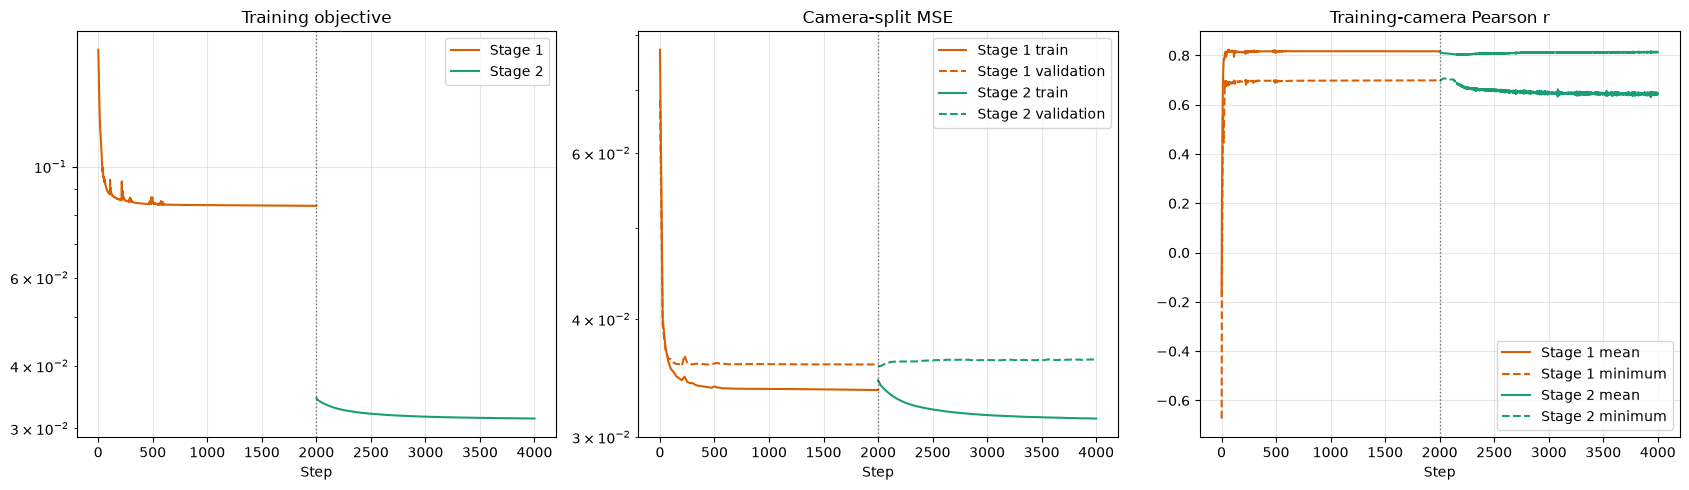

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for label, result, offset, color in (
    ("Stage 1", stage1_result, 0, "#d95f02"),
    ("Stage 2", stage2_result, STAGE1_STEPS, "#1b9e77"),
):
    steps = [offset + step for step in result.history["step"]]
    axes[0].plot(steps, result.history["loss"], label=label, color=color)
    eval_steps = [offset + row["step"] for row in result.evaluations]
    axes[1].plot(eval_steps, [row["train_mse"] for row in result.evaluations], label=f"{label} train", color=color)
    axes[1].plot(eval_steps, [row["validation_mse"] for row in result.evaluations], label=f"{label} validation", color=color, ls="--")
    axes[2].plot(steps, result.history["mean_r"], label=f"{label} mean", color=color)
    axes[2].plot(steps, result.history["min_r"], label=f"{label} minimum", color=color, ls="--")
for axis, title in zip(axes, ("Training objective", "Camera-split MSE", "Training-camera Pearson r")):
    axis.axvline(STAGE1_STEPS, color="k", ls=":", lw=1, alpha=0.5)
    axis.set_xlabel("Step")
    axis.set_title(title)
    axis.legend()
    axis.grid(alpha=0.3)
axes[0].set_yscale("log")
axes[1].set_yscale("log")
fig.tight_layout()
plt.show()

train MSE: 0.031379
validation MSE: 0.036229
All-camera mean r=0.8125, minimum r=0.6509


,MSE,MAE,Pearson_R,Split
Camera,,,,
315_bottom,0.016230,0.098852,0.650855,train
225_hor2,0.128349,0.278072,0.678191,validation
225_hor1,0.111774,0.254588,0.701228,train
0_bottom,0.021132,0.116382,0.711574,train
135_hor1,0.118165,0.285326,0.721229,train
315_top,0.013999,0.093383,0.729926,train
135_hor2,0.101821,0.252494,0.757228,train
315_hor2,0.032432,0.161616,0.771342,validation
315_hor1,0.032714,0.162702,0.772392,train


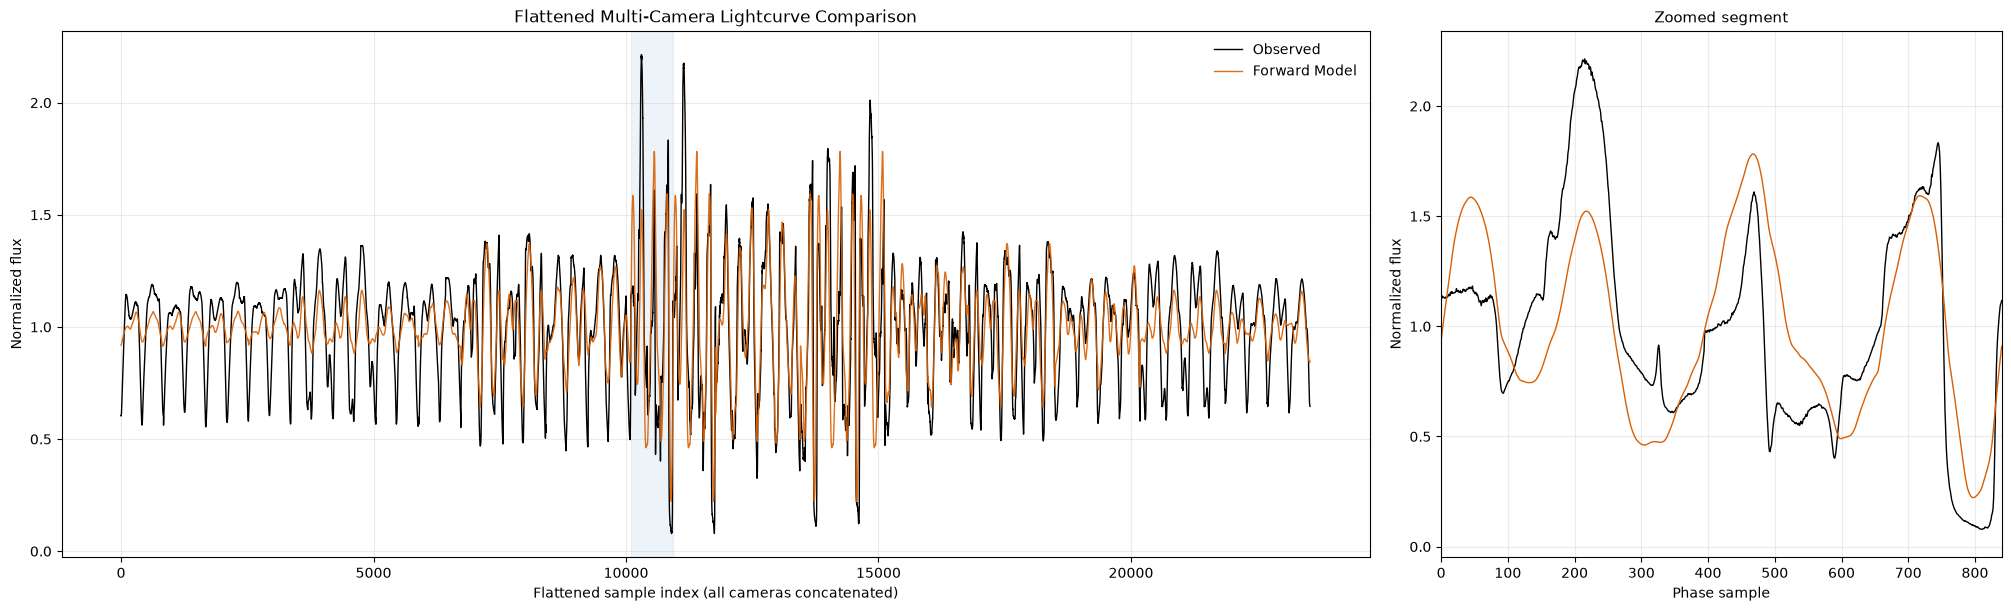

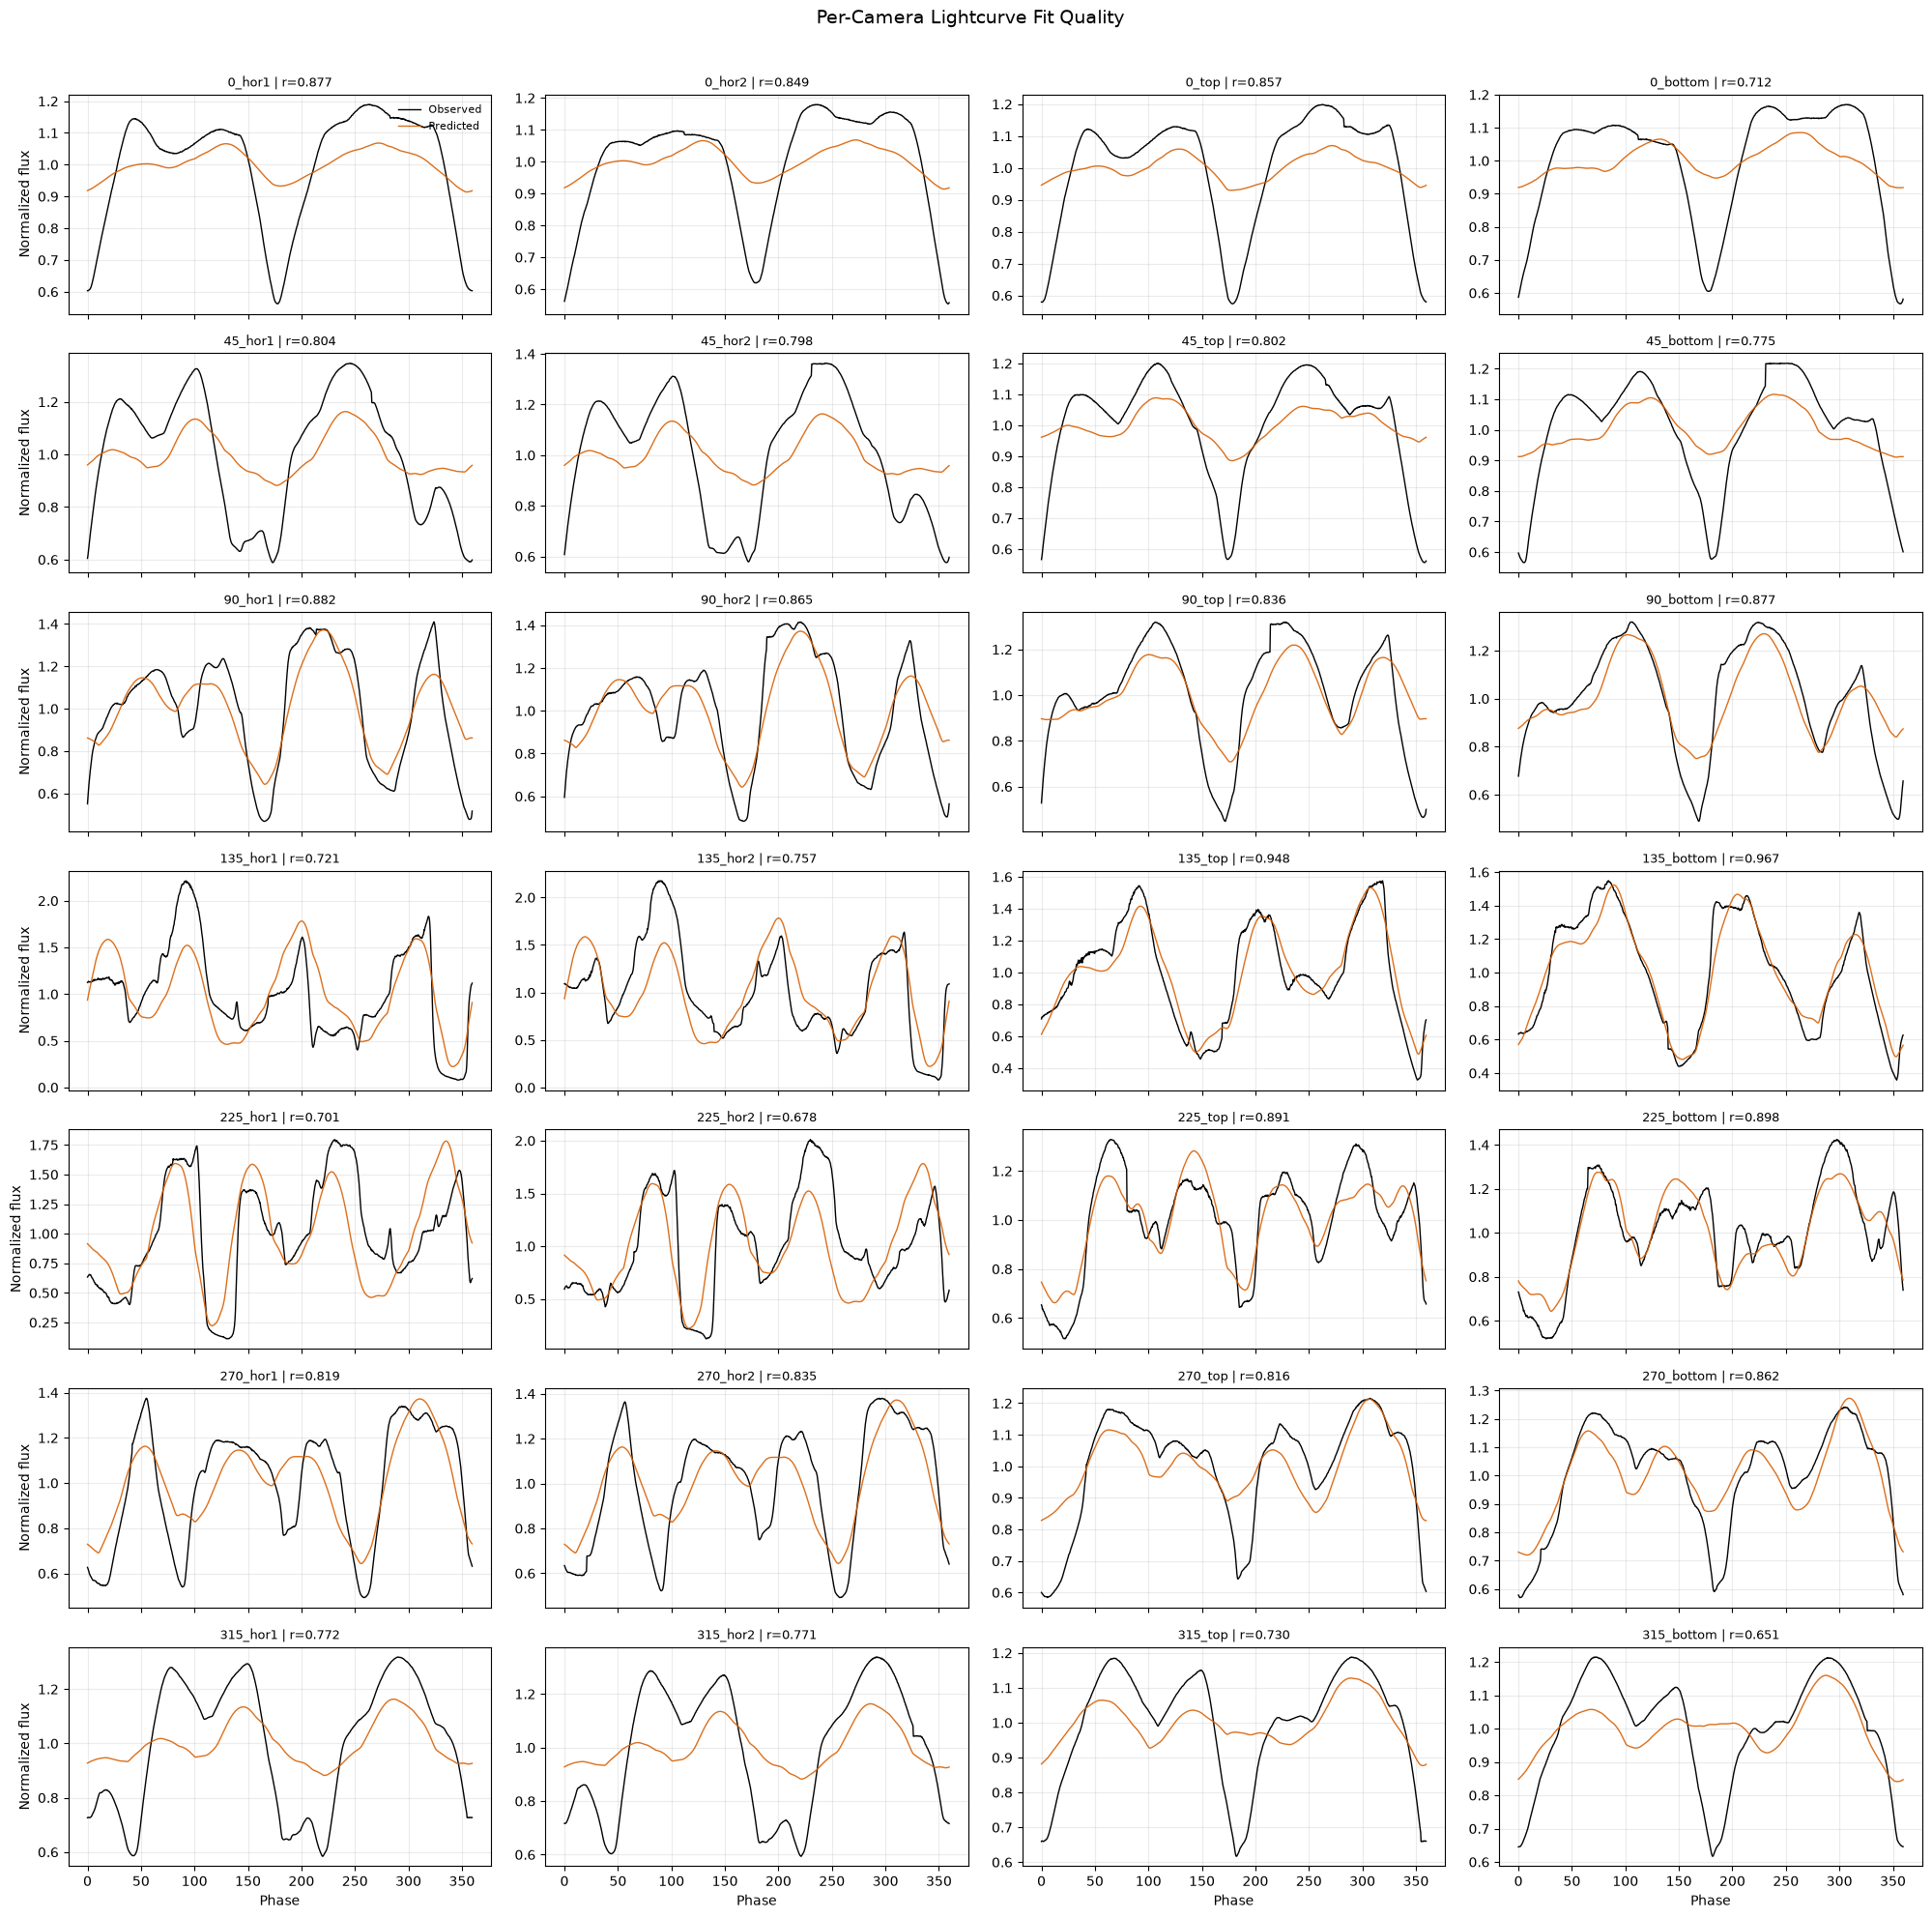

In [11]:
net.eval()
with torch.no_grad():
    _, deformed_final = net(base_vertices, base_normals)
    pred_norm = predicted_lightcurves(deformed_final[0])

per_camera_df = compute_per_camera_metrics(observed_norm, pred_norm, camera_names)
validation_names = {camera_names[index] for index in validation_indices.tolist()}
per_camera_df["Split"] = ["validation" if name in validation_names else "train" for name in camera_names]
for label, indices in (("train", train_indices), ("validation", validation_indices)):
    mse = compute_mse(observed_norm[indices], pred_norm[indices])
    print(f"{label} MSE: {float(mse):.6f}")
print(f"All-camera mean r={per_camera_df['Pearson_R'].mean():.4f}, minimum r={per_camera_df['Pearson_R'].min():.4f}")
display(per_camera_df.sort_values("Pearson_R"))

target_cam = "135_hor1"
fig, _ = plot_lightcurve_comparison(
    obs_norm=observed_norm.detach().cpu().numpy(),
    pred_norm=pred_norm.detach().cpu().numpy(),
    camera_keys=camera_names, target_cam_id=target_cam,
)
plt.show()
phase_deg = np.rad2deg(phases.detach().cpu().numpy())
fig, _ = plot_camera_grid(observed_norm, pred_norm, camera_names, phase_axis=phase_deg)
plt.show()

In [12]:
vertices_np = deformed_final[0].detach().cpu().numpy()
faces_np = faces.detach().cpu().numpy()
recon_mesh = trimesh.Trimesh(vertices=vertices_np, faces=faces_np, process=False)
fig_mesh = plot_interactive_mesh(
    vertices=vertices_np, faces=faces_np,
    title=f"Asteroid {ASTEROID_ID}: validation-selected INR+GCN ({faces_np.shape[0]} faces)",
    mesh_color="#c0b08a", show_edges=False,
)
fig_mesh.show()
print(f"Refined mesh bounds: {recon_mesh.bounds}; cylinder R={prior['R_CYLINDER']}, z in [-1, 1]")

reference_mesh = None
if REFERENCE_STL_PATH_EVAL.exists():
    reference_mesh = normalize_mesh_to_challenge_cylinder(
        trimesh.load_mesh(REFERENCE_STL_PATH_EVAL), prior["R_CYLINDER"],
    )
    reference_fig_mesh = plot_interactive_mesh(
        vertices=reference_mesh.vertices, faces=reference_mesh.faces,
        title=f"Asteroid {ASTEROID_ID}: true STL, evaluation only",
        mesh_color="#a0c0ff", show_edges=False,
    )
    reference_fig_mesh.show()
else:
    print(f"True STL unavailable at {REFERENCE_STL_PATH_EVAL}; skipping shape metrics.")

recon_path = RECON_DIR / f"{RUN_NAME}.stl"
recon_mesh.export(recon_path)
print(f"Saved refined mesh: {recon_path}")

Refined mesh bounds: [[-3.51175594 -3.15302706 -1.        ]
 [ 3.51175594  3.15302706  1.        ]]; cylinder R=3.95, z in [-1, 1]
True STL unavailable at /raid/data/iayad/challenge_data/AsteroidModel10_shape_secret/asteroid10.stl; skipping shape metrics.
Saved refined mesh: /home/opis/iayad/WORK/HAC-DTU/workspaces/ishak/recon/stabilized_plain_ellipsoid_ast10_seed42.stl


In [13]:
from hac.eval import relative_volume_difference_voxelized

VOXEL_PITCH = 0.05  # official filled-voxel measure, pitch on cylinder-normalized meshes

stage1_to_refined = np.linalg.norm(vertices_np - verts_s1_np, axis=1)
cylinder_scale = float(np.linalg.norm([prior["R_CYLINDER"], prior["R_CYLINDER"], 1.0]))
print(
    f"Stage-1 -> Stage-2 vertex shift: mean={stage1_to_refined.mean():.4f}, "
    f"max={stage1_to_refined.max():.4f} "
    f"({100 * stage1_to_refined.mean() / cylinder_scale:.2f}% of the cylinder diagonal)"
)

if reference_mesh is not None:
    stage1_mesh = trimesh.Trimesh(vertices=verts_s1_np, faces=faces_np, process=False)
    # Official challenge voxel measures (0 = identical, lower is better).
    print(f"Official voxel measures vs true STL (pitch={VOXEL_PITCH}); 0 = identical, lower is better:")
    for name, mesh in (("convex_prior", reference_mesh_norm), ("stage1", stage1_mesh), ("refined", recon_mesh)):
        measure1, measure2 = relative_volume_difference_voxelized(mesh, reference_mesh, pitch=VOXEL_PITCH)
        chamfer = mesh_reconstruction_metrics(mesh, reference_mesh, n_surface_samples=8192, pitch=0.04)["surface_chamfer"]
        print(
            f"  {name:12s} measure1 (1 - IoU)={measure1:.4f} | "
            f"measure2 (sym-diff/sum)={measure2:.4f} | surface Chamfer={chamfer:.4f}"
        )
    if REFERENCE_MESH_SOURCE == "true":
        print("ORACLE RUN: true geometry entered training; these are not self-supervised reconstruction results.")
else:
    print("True reference mesh unavailable: shape metrics were not computed.")


Stage-1 -> Stage-2 vertex shift: mean=0.3627, max=0.8434 (6.39% of the cylinder diagonal)
True reference mesh unavailable: shape metrics were not computed.
